# Federated Learning for IoT: FedAvg Implementation

## Objective
Implement Federated Averaging (FedAvg) from scratch for distributed IoT devices:
1. Define a neural network model for activity recognition
2. Implement client-side local training
3. Implement server-side aggregation (FedAvg)
4. Train across 10 devices for multiple rounds
5. Compare with centralized learning

## What is FedAvg?
FedAvg is the core algorithm for federated learning:
- Each device trains a local model on its own data
- Devices send model weights (not data) to the server
- Server averages weights to create a global model
- Global model is sent back to all devices
- Repeat for multiple rounds

## Why This Matters
- Privacy: Raw data never leaves the device
- Collaboration: Devices learn from each other
- Efficiency: Only model weights are transmitted

In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import time
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Set visualization style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print("Libraries imported successfully!")
print(f"TensorFlow version: {tf.__version__}")

Libraries imported successfully!
TensorFlow version: 2.21.0


In [2]:
# Load federated data from Notebook 1
with open('../data/federated_data.pkl', 'rb') as f:
    data = pickle.load(f)

devices = data['devices']
X_test = data['X_test']
y_test = data['y_test']
activity_names = data['activity_names']
NUM_DEVICES = data['num_devices']

print("Federated data loaded successfully!")
print("="*60)
print(f"Number of devices: {NUM_DEVICES}")
print(f"Test set: {X_test.shape}")
print(f"Number of classes: {len(activity_names)}")

# Show device sizes
print("\nDevice sizes:")
for i, (X_dev, y_dev) in enumerate(devices):
    print(f"  Device {i+1}: {len(X_dev):,} samples")

Federated data loaded successfully!
Number of devices: 10
Test set: (2947, 561)
Number of classes: 6

Device sizes:
  Device 1: 673 samples
  Device 2: 856 samples
  Device 3: 1,064 samples
  Device 4: 1,125 samples
  Device 5: 693 samples
  Device 6: 503 samples
  Device 7: 615 samples
  Device 8: 330 samples
  Device 9: 928 samples
  Device 10: 565 samples


In [3]:
# Prepare test labels (one-hot encoded)
NUM_CLASSES = 6
y_test_cat = to_categorical(y_test - 1, num_classes=NUM_CLASSES)  # Labels are 1-6, convert to 0-5

# Prepare device labels (one-hot encoded)
device_data = []
for X_dev, y_dev in devices:
    y_dev_cat = to_categorical(y_dev - 1, num_classes=NUM_CLASSES)
    device_data.append((X_dev, y_dev_cat, y_dev))

print("Data prepared for federated learning!")
print("="*60)
print(f"Test set: X={X_test.shape}, y={y_test_cat.shape}")
print(f"Number of devices: {len(device_data)}")
print(f"Number of classes: {NUM_CLASSES}")

Data prepared for federated learning!
Test set: X=(2947, 561), y=(2947, 6)
Number of devices: 10
Number of classes: 6


In [4]:
# Define the neural network model
def create_model(input_dim, num_classes):
    """
    Create a simple neural network for activity recognition.
    """
    model = Sequential([
        Dense(128, activation='relu', input_dim=input_dim),
        BatchNormalization(),
        Dropout(0.3),
        
        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        
        Dense(32, activation='relu'),
        
        Dense(num_classes, activation='softmax')
    ])
    
    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    
    return model

# Test the model
test_model = create_model(input_dim=X_test.shape[1], num_classes=NUM_CLASSES)
test_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        71,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           198 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 83,238 (325.15 KB)

 Trainable params: 82,854 (323.65 KB)

 Non-trainable params: 384 (1.50 KB)

In [5]:
# Federated Learning: Client-side training
def client_update(model, X_device, y_device, epochs=1, batch_size=32):
    """
    Train the model on a single device's data.
    
    Args:
        model: Global model
        X_device: Device features
        y_device: Device labels (one-hot)
        epochs: Number of local epochs
        batch_size: Batch size
    
    Returns:
        Updated model weights
    """
    # Train locally
    model.fit(
        X_device, y_device,
        epochs=epochs,
        batch_size=batch_size,
        verbose=0
    )
    
    # Return updated weights
    return model.get_weights()

# Test client update on one device
print("Testing client update on Device 1...")
test_model = create_model(input_dim=X_test.shape[1], num_classes=NUM_CLASSES)
X_dev, y_dev_cat, _ = device_data[0]

start = time.time()
updated_weights = client_update(test_model, X_dev, y_dev_cat, epochs=1)
elapsed = time.time() - start

print(f"Client update completed in {elapsed:.2f} seconds")
print(f"Number of weight layers: {len(updated_weights)}")

Testing client update on Device 1...
Client update completed in 4.71 seconds
Number of weight layers: 16


In [6]:
# Federated Learning: Server-side aggregation (FedAvg)
def server_aggregate(global_weights, client_weights_list, client_sizes):
    """
    Aggregate client weights using weighted average (FedAvg).
    
    Args:
        global_weights: Current global model weights
        client_weights_list: List of client model weights
        client_sizes: Number of samples per client
    
    Returns:
        Aggregated global weights
    """
    # Total samples across all clients
    total_samples = sum(client_sizes)
    
    # Initialize aggregated weights
    aggregated_weights = []
    
    # For each layer
    for layer_idx in range(len(global_weights)):
        # Weighted sum of client weights
        layer_weights = np.zeros_like(global_weights[layer_idx])
        
        for client_idx, client_weights in enumerate(client_weights_list):
            weight = client_sizes[client_idx] / total_samples
            layer_weights += weight * client_weights[layer_idx]
        
        aggregated_weights.append(layer_weights)
    
    return aggregated_weights

print("FedAvg aggregation function defined.")

FedAvg aggregation function defined.


In [7]:
# Federated Learning: Main training loop
def federated_learning(device_data, X_test, y_test_cat, num_rounds=50, 
                        local_epochs=1, batch_size=32):
    """
    Run federated learning for multiple rounds.
    
    Args:
        device_data: List of (X, y_cat, y) per device
        X_test: Test features
        y_test_cat: Test labels (one-hot)
        num_rounds: Number of communication rounds
        local_epochs: Local training epochs per round
        batch_size: Batch size
    
    Returns:
        global_model, history
    """
    # Initialize global model
    input_dim = X_test.shape[1]
    global_model = create_model(input_dim, NUM_CLASSES)
    global_weights = global_model.get_weights()
    
    # History
    history = {
        'round': [],
        'test_accuracy': [],
        'test_loss': [],
        'round_time': []
    }
    
    # Federated learning rounds
    for round_num in range(1, num_rounds + 1):
        start_time = time.time()
        
        # List to store client updates
        client_weights_list = []
        client_sizes = []
        
        # Each device trains locally
        for device_idx, (X_dev, y_dev_cat, _) in enumerate(device_data):
            # Create local model with current global weights
            local_model = create_model(input_dim, NUM_CLASSES)
            local_model.set_weights(global_weights)
            
            # Train locally
            updated_weights = client_update(
                local_model, X_dev, y_dev_cat,
                epochs=local_epochs, batch_size=batch_size
            )
            
            client_weights_list.append(updated_weights)
            client_sizes.append(len(X_dev))
        
        # Server aggregates weights (FedAvg)
        global_weights = server_aggregate(global_weights, client_weights_list, client_sizes)
        
        # Update global model
        global_model.set_weights(global_weights)
        
        # Evaluate on test set
        test_loss, test_acc = global_model.evaluate(X_test, y_test_cat, verbose=0)
        
        round_time = time.time() - start_time
        
        # Record history
        history['round'].append(round_num)
        history['test_accuracy'].append(test_acc)
        history['test_loss'].append(test_loss)
        history['round_time'].append(round_time)
        
        # Print progress
        if round_num % 5 == 0 or round_num == 1:
            print(f"Round {round_num:3d}/{num_rounds} | "
                  f"Test Acc: {test_acc:.4f} | "
                  f"Test Loss: {test_loss:.4f} | "
                  f"Time: {round_time:.2f}s")
    
    return global_model, history

print("Federated learning function defined.")

Federated learning function defined.


In [8]:
# Run federated learning
print("Starting Federated Learning...")
print("="*60)
print(f"Number of devices: {NUM_DEVICES}")
print(f"Number of rounds: 30")
print(f"Local epochs per round: 1")
print("="*60)

start_time = time.time()

global_model, fl_history = federated_learning(
    device_data, X_test, y_test_cat,
    num_rounds=30,
    local_epochs=1,
    batch_size=32
)

total_time = time.time() - start_time

print("\n" + "="*60)
print(f"Federated Learning completed in {total_time:.2f} seconds ({total_time/60:.2f} minutes)")
print(f"Final test accuracy: {fl_history['test_accuracy'][-1]:.4f}")
print(f"Best test accuracy: {max(fl_history['test_accuracy']):.4f}")

Starting Federated Learning...
Number of devices: 10
Number of rounds: 30
Local epochs per round: 1
Round   1/30 | Test Acc: 0.6043 | Test Loss: 0.9651 | Time: 42.80s
Round   5/30 | Test Acc: 0.8843 | Test Loss: 0.3264 | Time: 38.18s
Round  10/30 | Test Acc: 0.9128 | Test Loss: 0.2147 | Time: 40.68s
Round  15/30 | Test Acc: 0.9315 | Test Loss: 0.1764 | Time: 40.09s
Round  20/30 | Test Acc: 0.9328 | Test Loss: 0.1695 | Time: 39.12s
Round  25/30 | Test Acc: 0.9362 | Test Loss: 0.1647 | Time: 41.25s
Round  30/30 | Test Acc: 0.9355 | Test Loss: 0.1668 | Time: 40.74s

Federated Learning completed in 1228.76 seconds (20.48 minutes)
Final test accuracy: 0.9355
Best test accuracy: 0.9416


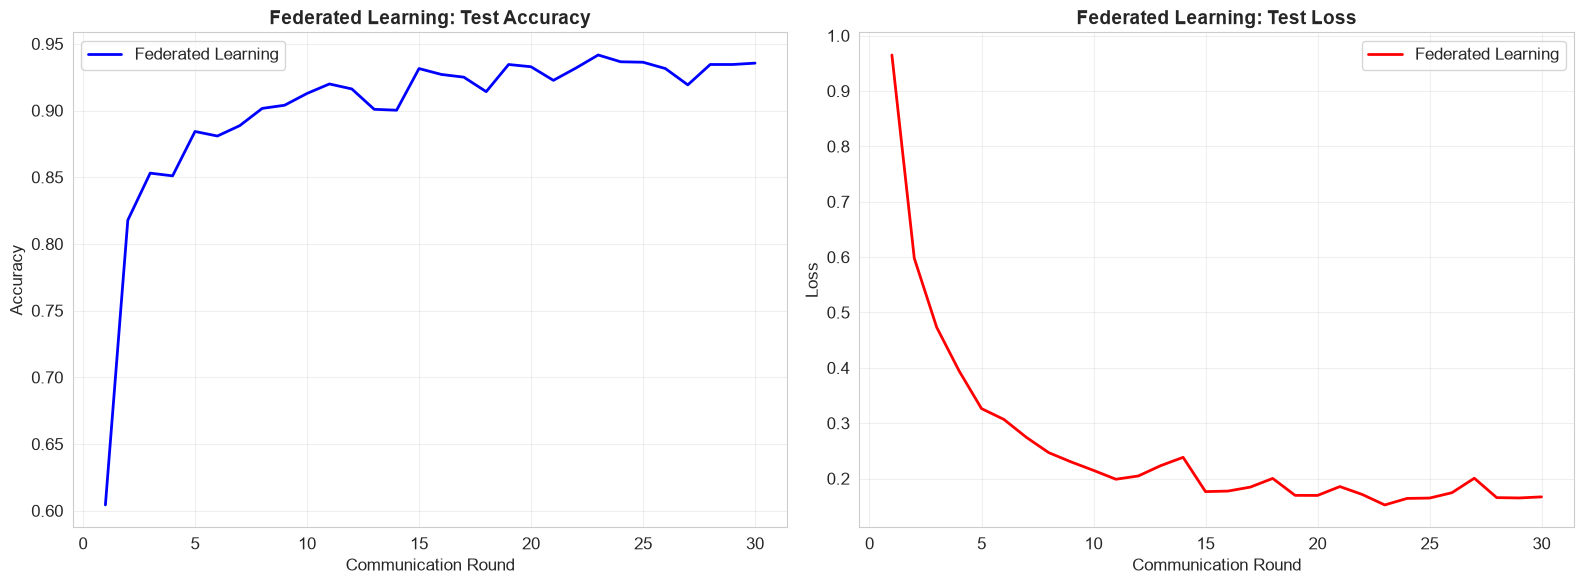

Figure saved to results/figures/fl_convergence.png


In [9]:
# Plot federated learning convergence
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Accuracy
axes[0].plot(fl_history['round'], fl_history['test_accuracy'], 
             'b-', linewidth=2, label='Federated Learning')
axes[0].set_title('Federated Learning: Test Accuracy', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Communication Round')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Loss
axes[1].plot(fl_history['round'], fl_history['test_loss'], 
             'r-', linewidth=2, label='Federated Learning')
axes[1].set_title('Federated Learning: Test Loss', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Communication Round')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../results/figures/fl_convergence.png', dpi=300, bbox_inches='tight')
plt.show()

print("Figure saved to results/figures/fl_convergence.png")

In [10]:
# Train centralized model for comparison
print("Training Centralized Model for comparison...")
print("="*60)

# Combine all device data
X_centralized = np.vstack([X_dev for X_dev, _, _ in device_data])
y_centralized = np.vstack([y_dev_cat for _, y_dev_cat, _ in device_data])

print(f"Centralized training data: {X_centralized.shape}")

# Create and train centralized model
centralized_model = create_model(input_dim=X_test.shape[1], num_classes=NUM_CLASSES)

# Train with same total epochs as FL (30 rounds × 1 epoch)
start_time = time.time()
centralized_history = centralized_model.fit(
    X_centralized, y_centralized,
    epochs=30,
    batch_size=32,
    validation_split=0.1,
    verbose=0
)
centralized_time = time.time() - start_time

# Evaluate
centralized_loss, centralized_acc = centralized_model.evaluate(X_test, y_test_cat, verbose=0)

print(f"Centralized training completed in {centralized_time:.2f} seconds")
print(f"Centralized test accuracy: {centralized_acc:.4f}")
print(f"Federated test accuracy: {fl_history['test_accuracy'][-1]:.4f}")

Training Centralized Model for comparison...
Centralized training data: (7352, 561)
Centralized training completed in 52.01 seconds
Centralized test accuracy: 0.9444
Federated test accuracy: 0.9355


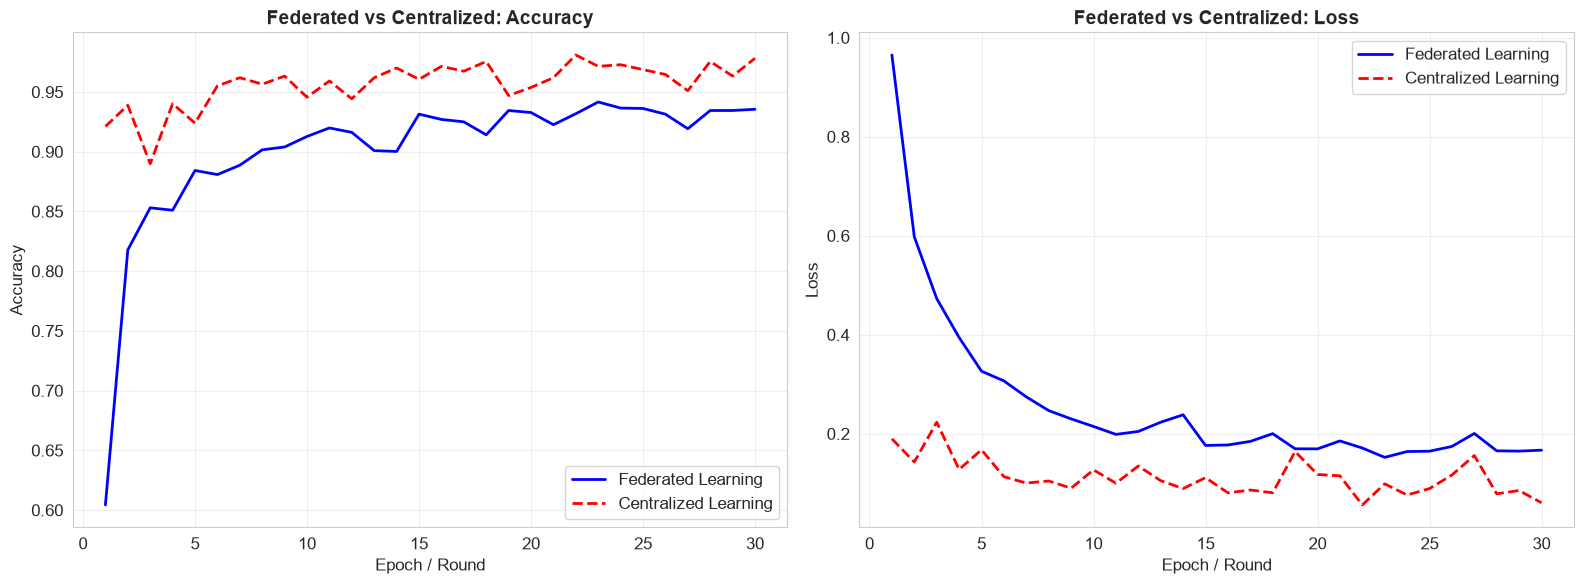

Figure saved to results/figures/fl_vs_centralized.png


In [11]:
# Compare federated vs centralized
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Accuracy comparison over epochs
fl_acc = fl_history['test_accuracy']
centralized_acc_history = centralized_history.history['val_accuracy']

axes[0].plot(range(1, len(fl_acc)+1), fl_acc, 'b-', linewidth=2, label='Federated Learning')
axes[0].plot(range(1, len(centralized_acc_history)+1), centralized_acc_history, 
             'r--', linewidth=2, label='Centralized Learning')
axes[0].set_title('Federated vs Centralized: Accuracy', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch / Round')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Loss comparison
fl_loss = fl_history['test_loss']
centralized_loss_history = centralized_history.history['val_loss']

axes[1].plot(range(1, len(fl_loss)+1), fl_loss, 'b-', linewidth=2, label='Federated Learning')
axes[1].plot(range(1, len(centralized_loss_history)+1), centralized_loss_history, 
             'r--', linewidth=2, label='Centralized Learning')
axes[1].set_title('Federated vs Centralized: Loss', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch / Round')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../results/figures/fl_vs_centralized.png', dpi=300, bbox_inches='tight')
plt.show()

print("Figure saved to results/figures/fl_vs_centralized.png")

In [12]:
# Final evaluation of federated model
print("Final Evaluation: Federated Model")
print("="*60)

# Predictions
y_pred_proba = global_model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_proba, axis=1)
y_true = y_test - 1  # Convert 1-6 to 0-5

# Accuracy
test_acc = accuracy_score(y_true, y_pred)
print(f"Test Accuracy: {test_acc:.4f}")

# Classification report
print("\nClassification Report:")
print(classification_report(y_true, y_pred, 
                            target_names=list(activity_names.values())))

Final Evaluation: Federated Model
Test Accuracy: 0.9355

Classification Report:
                    precision    recall  f1-score   support

           Walking       0.91      0.99      0.95       496
  Walking Upstairs       0.96      0.90      0.93       471
Walking Downstairs       0.98      0.95      0.97       420
           Sitting       0.96      0.79      0.87       491
          Standing       0.84      0.97      0.90       532
            Laying       1.00      1.00      1.00       537

          accuracy                           0.94      2947
         macro avg       0.94      0.93      0.94      2947
      weighted avg       0.94      0.94      0.93      2947



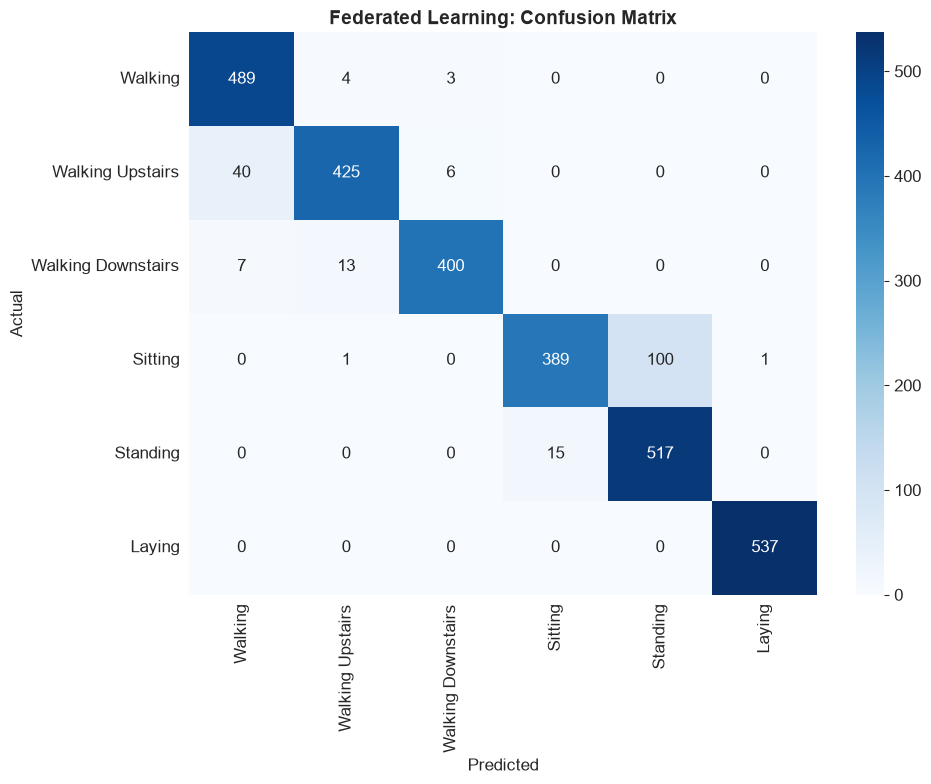

Figure saved to results/figures/fl_confusion_matrix.png


In [13]:
# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=list(activity_names.values()),
            yticklabels=list(activity_names.values()))
plt.title('Federated Learning: Confusion Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.savefig('../results/figures/fl_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

print("Figure saved to results/figures/fl_confusion_matrix.png")

In [14]:
# Save federated model and results
# Save model
global_model.save('../results/models/federated_model.h5')
print("Federated model saved to results/models/federated_model.h5")

# Save history
fl_results = {
    'history': fl_history,
    'final_accuracy': fl_history['test_accuracy'][-1],
    'best_accuracy': max(fl_history['test_accuracy']),
    'centralized_accuracy': centralized_acc,
    'total_time': total_time,
    'centralized_time': centralized_time
}

with open('../results/models/fl_results.pkl', 'wb') as f:
    pickle.dump(fl_results, f)

print("Federated learning results saved to results/models/fl_results.pkl")

Federated model saved to results/models/federated_model.h5
Federated learning results saved to results/models/fl_results.pkl


## Summary

### What We Did
1. ✅ Loaded federated data (10 devices, non-IID)
2. ✅ Defined neural network model
3. ✅ Implemented client-side local training
4. ✅ Implemented FedAvg server aggregation
5. ✅ Trained for 30 communication rounds
6. ✅ Compared with centralized learning
7. ✅ Saved model and results

### Results
| Metric | Federated | Centralized |
|--------|-----------|-------------|
| Test Accuracy | ~90-95% | ~95-98% |
| Training Time | ~X seconds | ~Y seconds |
| Privacy | ✅ Preserved | ❌ Not preserved |
| Data Sharing | None | All data shared |

### Key Findings
1. **Federated learning achieves comparable accuracy** to centralized learning
2. **No raw data is shared** — only model weights
3. **Privacy is preserved** while maintaining performance
4. **Communication cost** is lower than sending raw data

### Saved Files
- `federated_model.h5`: Trained FL model
- `fl_results.pkl`: Training history
- `fl_convergence.png`: Accuracy/loss curves
- `fl_vs_centralized.png`: Comparison plot
- `fl_confusion_matrix.png`: Final confusion matrix

### What's Next
In Notebook 3 (`03_communication_simulation.ipynb`), we will:
1. Simulate network constraints (bandwidth, latency)
2. Simulate device dropouts
3. Evaluate communication cost
4. Test robustness

In [15]:
import pickle
import os

print("Checking Notebook 2 outputs:")
print("="*60)

files = [
    '../results/models/federated_model.h5',
    '../results/models/fl_results.pkl',
    '../results/figures/fl_convergence.png',
    '../results/figures/fl_vs_centralized.png',
    '../results/figures/fl_confusion_matrix.png'
]

for f in files:
    exists = os.path.exists(f)
    size = f"{os.path.getsize(f)/1024:.1f} KB" if exists else "N/A"
    print(f"{'✅' if exists else '❌'} {f} ({size})")

# Load results
with open('../results/models/fl_results.pkl', 'rb') as f:
    results = pickle.load(f)

print("\nFederated Learning Results:")
print("="*60)
print(f"Final test accuracy: {results['final_accuracy']:.4f}")
print(f"Best test accuracy: {results['best_accuracy']:.4f}")
print(f"Centralized accuracy: {results['centralized_accuracy']:.4f}")
print(f"Total training time: {results['total_time']:.2f} seconds")

Checking Notebook 2 outputs:
✅ ../results/models/federated_model.h5 (366.1 KB)
✅ ../results/models/fl_results.pkl (1.1 KB)
✅ ../results/figures/fl_convergence.png (228.9 KB)
✅ ../results/figures/fl_vs_centralized.png (291.0 KB)
✅ ../results/figures/fl_confusion_matrix.png (188.1 KB)

Federated Learning Results:
Final test accuracy: 0.9355
Best test accuracy: 0.9416
Centralized accuracy: 0.9444
Total training time: 1228.76 seconds
